# BIOT 6900 · Module 6, Part 3 — Graded Assignment: PRS Portability on Real Data

You now run the full workflow yourself, on **real 1000 Genomes genotypes** with a **published Alzheimer's score from the PGS Catalog** (PGS000334, which includes APOE, connecting to your Part I work): harmonize the alleles, compute the PRS, and evaluate discrimination, calibration, and the portability problem across ancestry groups. Then you write it up.

Completed analysis for Shreegowri MB. All results below are generated from the supplied files with `USE_DEMO = False`.


### Data (provided on Canvas)

Download **`data.zip`** from Canvas and unzip it next to the notebook, so you have a `data/` folder with the four CSV files and `README.md`. Keep the folder named `data`, and read the README (it documents the cohort, the simulated phenotype, and the APOE caveat).

| File | Columns | Notes |
|---|---|---|
| `genotypes.csv` | one column per variant, rows = people | dosages 0/1/2, **counting the ALT allele** |
| `variants.csv` | `variant`, `ref`, `alt` | the REF/ALT nucleotides, same build as the genotypes |
| `score.csv` | `variant`, `effect_allele`, `other_allele`, `weight` | the provided Alzheimer's score (PGS000334); alleles as published |
| `meta.csv` | `ancestry`, `age`, `phenotype` | ancestry = EUR/AFR/EAS/SAS/AMR; phenotype is 1 = case |

> **This is a graded run, so it must use real data.** The loader **stops with an error** unless all four files are present. A `USE_DEMO` flag exists only so you can prototype on synthetic data while you wait for files; **it must be `False` in your submission.**

> ⚠️ **The phenotype is simulated.** 1000 Genomes has no disease labels, so `phenotype` is simulated. The PRS and its distribution across ancestries are computed on real inputs; AUC and calibration use the simulated label and are illustrative. Say this in your write-up.

> **APOE caveat.** In this simulated cohort the LD proxy for APOE ε4 is almost absent in African-ancestry samples, so ε4 appears to have little effect in AFR here and the score runs near chance there. That is an artifact of the simulation design, **not real biology**: ε4 is a risk allele across ancestries. Keep that distinction in your write-up.

> **Proof of real data.** Section 2 prints a fingerprint (file checksums, counts). **Paste it into your report** so the grader can confirm you ran real data.


### Scope of this submission

I used the supplied **Alzheimer’s disease** panel and **PGS000334** (22 variants, GRCh37), as specified in this starter and the data README. My broader Part I project is PDAC, but this small genotype panel cannot support a PDAC score. This submission is the supplied Alzheimer’s portability exercise, not a PDAC risk analysis. A disease-matched PDAC extension would require new genotype coverage and an appropriate score.


## 0. Setup

In [1]:
import os, hashlib, json, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import display
import sklearn, scipy

NU_RED, NU_COOL, NU_GREY = '#C8102E', '#1E2028', '#6E7178'
POP_COLORS = {'EUR':'#222B45','AFR':'#C8102E','EAS':'#277DA8','SAS':'#99702F','AMR':'#347D68'}
rng = np.random.default_rng(6900)
USE_DEMO = False  # Required for the graded submission; strict loader below is unchanged.
Path('figures').mkdir(exist_ok=True)
Path('results').mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':110, 'font.size':10, 'axes.spines.top':False,
                     'axes.spines.right':False, 'savefig.bbox':'tight'})
def save_figure(fig, name):
    fig.savefig(Path('figures') / f'{name}.png', dpi=200)
    fig.savefig(Path('figures') / f'{name}.pdf')


## 1. Load the data  *(provided, do not edit)*

Strict loader: with `USE_DEMO = False` it requires all four real files and refuses to run otherwise. The demo path is clearly labelled and is never acceptable for grading.

In [2]:
BASES = np.array(list("ACGT"))
def _make_demo_cohort(seed=6900):
    r = np.random.default_rng(seed)
    pops = {"EUR":(600,0.92,0.05,0.14),"AFR":(600,0.40,0.15,0.22),"EAS":(500,0.58,0.12,0.09),
            "SAS":(500,0.66,0.09,0.09),"AMR":(500,0.55,0.07,0.11)}   # n, tag-rho, drift, APOE freq
    M = 80
    b = r.normal(0, 0.15, M); b[0] = 1.3
    w_true = b * 0.92
    base = r.uniform(0.15, 0.5, M)
    Gt, Gc, anc, ages = [], [], [], []
    for pop,(n,rho,drift,apoe) in pops.items():
        f = np.clip(base + r.normal(0,drift,M), 0.03, 0.97); f[0] = apoe; thr = norm.ppf(f)
        gc = np.zeros((n,M)); gt = np.zeros((n,M))
        for _ in range(2):
            L = r.normal(size=(n,M)); Z = r.normal(size=(n,M))
            gc += (L<thr); gt += ((rho*L + np.sqrt(1-rho**2)*Z) < thr)
        Gt.append(gt); Gc.append(gc); anc += [pop]*n; ages.append(r.normal(60,8,n))
    Gt = np.vstack(Gt); Gc = np.vstack(Gc); anc = np.array(anc); age = np.concatenate(ages)
    lin = Gc @ b + 0.03*(age-60); b0 = np.log(0.30/0.70) - lin.mean()
    y = (r.uniform(size=len(lin)) < 1/(1+np.exp(-(b0+lin)))).astype(int)
    variants = [f"rs_tag_{i:03d}" for i in range(M)]
    # real nucleotides: pick ref != alt; dosages count ALT
    ref = r.choice(BASES, M); alt = np.array([r.choice(BASES[BASES!=ref[i]]) for i in range(M)])
    geno = pd.DataFrame(Gt, columns=variants)
    vtab = pd.DataFrame({"variant":variants, "ref":ref, "alt":alt})
    # 25% of rows report the REF allele as effect allele, with the weight's sign reversed
    report_ref = r.random(M) < 0.25
    eff = np.where(report_ref, ref, alt); oth = np.where(report_ref, alt, ref)
    wrep = np.where(report_ref, -w_true, w_true)
    score = pd.DataFrame({"variant":variants, "effect_allele":eff, "other_allele":oth, "weight":wrep})
    meta  = pd.DataFrame({"ancestry":anc, "age":age, "phenotype":y})
    return geno, vtab, score, meta

REAL_FILES = ["genotypes.csv","variants.csv","score.csv","meta.csv"]
def _sha8(path):
    h = hashlib.sha256(open(path,"rb").read()).hexdigest()[:8]
    return h

def load_data(path="data"):
    present = [f for f in REAL_FILES if os.path.exists(os.path.join(path,f))]
    if not USE_DEMO:
        missing = [f for f in REAL_FILES if f not in present]
        if missing:
            raise FileNotFoundError(
                "GRADED RUN requires all four files in ./%s/ . Missing: %s .  "
                "Set USE_DEMO=True ONLY to prototype on synthetic data; it must be False for submission."
                % (path, ", ".join(missing)))
        geno=pd.read_csv(os.path.join(path,"genotypes.csv"))
        vtab=pd.read_csv(os.path.join(path,"variants.csv"))
        score=pd.read_csv(os.path.join(path,"score.csv"))
        meta=pd.read_csv(os.path.join(path,"meta.csv"))
        info={"source":"REAL","hashes":{f:_sha8(os.path.join(path,f)) for f in REAL_FILES}}
        print("="*64); print("  RUNNING ON REAL DATA"); print("="*64)
    else:
        print("="*64); print("  USE_DEMO=True  ->  SYNTHETIC demo cohort  (NOT FOR GRADING)"); print("="*64)
        geno,vtab,score,meta=_make_demo_cohort(); info={"source":"DEMO","hashes":None}
    return geno, vtab, score, meta, info

geno, variants, score, meta, info = load_data()

  RUNNING ON REAL DATA


## 2. Proof of real data  *(paste this block into your report)*

In [3]:
ancestry_counts = {k:int(v) for k,v in meta['ancestry'].value_counts().items()}
proof_lines = [f"source      : {info['source']}", f"people      : {len(meta)}",
               f"score size  : {len(score)} variants",
               f"by ancestry : {ancestry_counts}"]
if info['source'] == 'REAL':
    proof_lines += [f'  {f}: sha256 {h}' for f,h in info['hashes'].items()]
else:
    proof_lines.append('  DEMO cohort - not acceptable for your graded submission')
proof_text = '\n'.join(proof_lines)
print(proof_text)
Path('results/proof_of_data.txt').write_text(proof_text + '\n')
assert USE_DEMO is False and info['source'] == 'REAL'
# Full digests supplement the eight-character fingerprints requested in the starter.
pd.DataFrame([{'file':f, 'sha256':hashlib.sha256(Path('data',f).read_bytes()).hexdigest()}
              for f in REAL_FILES]).to_csv('results/input_sha256.csv',index=False)


source      : REAL
people      : 2336
score size  : 22 variants
by ancestry : {'AFR': 500, 'EAS': 500, 'EUR': 500, 'SAS': 489, 'AMR': 347}
  genotypes.csv: sha256 9cf41a1f
  variants.csv: sha256 f7a87d3f
  score.csv: sha256 7f80e8ff
  meta.csv: sha256 6cc55b6e


## 3.1 Harmonize alleles: keep / flip / drop  

For each variant, compare the score's `effect_allele` with that variant's REF and ALT:
- equals **ALT** -> keep the dosage and weight as is,
- equals **REF** -> flip the dosage (`2 - dosage`),
- equals **neither** -> drop the variant.

Report how many you used, flipped, and dropped.

In [4]:
# Validate identity before any matrix operation. No phenotype or dosage is imputed.
assert geno['sample_id'].is_unique and meta['sample_id'].is_unique
assert geno['sample_id'].equals(meta['sample_id']), 'Genotype/metadata row order differs'
assert score['variant'].is_unique and variants['variant'].is_unique
assert geno.columns.is_unique
assert not meta[['ancestry','age','phenotype']].isna().any().any()
assert set(meta['ancestry']) == set(POP_COLORS)
assert set(meta['phenotype']) == {0,1}
assert np.isfinite(meta['age']).all()
for col in ['effect_allele','other_allele']:
    score[col] = score[col].astype(str).str.strip().str.upper()
for col in ['ref','alt']:
    variants[col] = variants[col].astype(str).str.strip().str.upper()
assert (variants['ref'] != variants['alt']).all()
assert variants[['ref','alt']].isin(list('ACGT')).all().all()
score['weight'] = pd.to_numeric(score['weight'],errors='raise')
assert np.isfinite(score['weight']).all()

not_found = score.loc[~score['variant'].isin(geno.columns), 'variant'].tolist()
shared = [v for v in score['variant'] if v in geno.columns]
assert shared, 'No score variants overlap the panel; do not compute a partial zero score'
assert set(shared) <= set(variants['variant'])
G = geno[shared].to_numpy(dtype=float).copy()
assert np.isfinite(G).all() and np.isin(G,[0,1,2]).all()
G_alt = G.copy()
s = score.set_index('variant').loc[shared]
v = variants.set_index('variant').loc[shared]
eff = s['effect_allele'].to_numpy()
ref, alt = v['ref'].to_numpy(), v['alt'].to_numpy()
w = s['weight'].to_numpy(dtype=float)
keep = eff == alt
flip = eff == ref
drop = ~(keep | flip)
# The supplied files are forward-strand GRCh37. Audit the other allele too.
expected_other = np.where(keep, ref, alt)
other_ok = s['other_allele'].to_numpy() == expected_other
assert other_ok[~drop].all(), 'Other-allele mismatch: investigate before scoring'
audit = s.reset_index().assign(ref=ref, alt=alt,
    action=np.where(keep,'keep',np.where(flip,'flip','drop')),
    other_allele_matches=other_ok)
audit.to_csv('results/allele_harmonization.csv',index=False)
G[:,flip] = 2 - G[:,flip]  # Count the published effect allele, retaining its weight.
used = ~drop
G, w = G[:,used], w[used]
assert G.shape == (len(meta),int(used.sum()))
assert len(score) == len(not_found) + int(used.sum()) + int(drop.sum())
harm = {'score_variants':len(score),'panel_overlap':len(shared),'kept':int(keep.sum()),
        'flipped':int(flip.sum()),'used':int(used.sum()),
        'allele_mismatch_dropped':int(drop.sum()),'not_in_panel':len(not_found)}
print(f"used {harm['used']}  flipped {harm['flipped']}  dropped {harm['allele_mismatch_dropped']}")
print(f"kept unchanged {harm['kept']}  not in panel {harm['not_in_panel']}")
print('No missing dosages; sample IDs are unique and identically ordered.')
display(audit)
Path('results/harmonization_summary.json').write_text(json.dumps(harm,indent=2))


used 22  flipped 13  dropped 0
kept unchanged 9  not in panel 0
No missing dosages; sample IDs are unique and identically ordered.


,variant,effect_allele,other_allele,weight,ref,alt,action,other_allele_matches
0,rs6656401,A,G,0.14,A,G,flip,True
1,rs744373,A,G,-0.14,A,G,flip,True
2,rs7419666,T,C,-0.06,T,C,flip,True
3,rs9381563,T,C,-0.08,C,T,keep,True
4,rs1476679,T,C,0.09,C,T,keep,True
5,rs7791765,T,G,0.09,T,G,flip,True
6,rs17057043,A,G,0.08,G,A,keep,True
7,rs11136000,T,C,-0.11,T,C,flip,True
8,rs7920721,A,G,-0.07,A,G,flip,True
9,rs12292911,A,G,0.06,G,A,keep,True


146

### My interpretation of allele harmonization

I used all **22/22** score variants: **9 kept unchanged, 13 flipped, 0 dropped for allele mismatch and 0 absent from the panel**. The genotype file counts ALT, while the published weight applies to the effect allele. So, whenever REF is the effect allele, I count `2 − ALT dosage`. I do not also reverse the weight because that would change the score twice. I checked the other allele, duplicate identifiers, dosage range and sample order before scoring.

For example, rs429358 has T as REF/effect allele, C as ALT, and a weight of −1.13. ALT dosage 0 becomes effect-allele dosage 2, contributing −2.26; ALT dosage 2 becomes effect-allele dosage 0, contributing 0. Therefore more C copies increase the total score relative to T copies. This is consistent with the score coding and does not establish an APOE haplotype diagnosis. These files are documented as forward-strand GRCh37; this simple rule would not resolve arbitrary strand or genome-build mismatches in another dataset.


## 3.2 Compute the PRS  

In [5]:
prs = G @ w
# All supplied weights have two decimal places. Remove floating-point noise in
# tied sums (at 12 decimals, far below input precision) before ranking/cutoffs.
prs = np.round(prs,12)
assert np.isfinite(prs).all() and prs.std(ddof=0) > 0
prs_z = (prs - prs.mean()) / prs.std(ddof=0)
meta['prs_raw'], meta['prs'] = prs, prs_z
assert np.isclose(prs_z.mean(),0) and np.isclose(prs_z.std(ddof=0),1)
print('PRS computed for',len(prs_z),'people')
print(f'Raw mean = {prs.mean():.6f}; raw SD (ddof=0) = {prs.std(ddof=0):.6f}')
print(f'Standardized mean = {prs_z.mean():.6f}; SD = {prs_z.std(ddof=0):.6f}')


PRS computed for 2336 people
Raw mean = -2.430646; raw SD (ddof=0) = 0.697097
Standardized mean = -0.000000; SD = 1.000000


### My interpretation of the PRS calculation

I calculated `PRS = aligned dosages @ published weights`, then standardized it using the **whole cohort** mean and population SD (`ddof=0`). The raw mean is **−2.430646** and SD is **0.697097**. Negative scores are not negative probabilities. They reflect the allele coding and weights; the standardized score tells me relative position within this particular reference cohort.

I rounded the sums to 12 decimal places only to remove machine-precision differences between tied scores; the supplied weights have two decimal places. Pooled standardization changes units, but it does not remove ancestry-specific distribution shifts or improve discrimination.


## 3.3 Distribution shift and a single cutoff  

Plot the PRS distribution per ancestry, then show what one fixed cutoff does: take the whole-cohort top-10% PRS value and report the fraction of each ancestry group above it.

Pooled 90th percentile = 1.492830 SD; rule: PRS > cutoff
Selected 232/2336 (9.932%)
Exactly on cutoff: 8; ties are excluded by the strict > rule.


,n,mean_prs,sd_prs,selected,fraction_selected,simulated_cases,simulated_case_fraction,percent_selected
ancestry,,,,,,,,
EUR,500,0.0362,0.9427,39,0.0780,157,0.3140,7.8000
AFR,500,0.7442,1.1125,139,0.2780,187,0.3740,27.8000
EAS,500,-0.4716,0.8092,11,0.0220,140,0.2800,2.2000
SAS,489,-0.2452,0.7781,21,0.0429,125,0.2556,4.2945
AMR,347,-0.0995,0.8173,22,0.0634,92,0.2651,6.3401


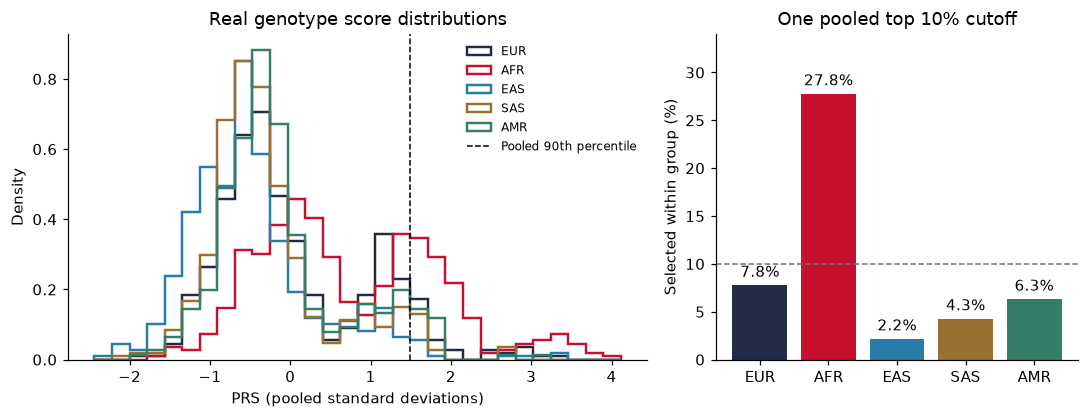

In [6]:
cutoff = np.quantile(meta['prs'],0.90)
meta['above_pooled_cutoff'] = meta['prs'] > cutoff
distribution = meta.groupby('ancestry').agg(
    n=('prs','size'), mean_prs=('prs','mean'), sd_prs=('prs','std'),
    selected=('above_pooled_cutoff','sum'), fraction_selected=('above_pooled_cutoff','mean'),
    simulated_cases=('phenotype','sum'), simulated_case_fraction=('phenotype','mean')
).reindex(POP_COLORS)
distribution['percent_selected'] = 100*distribution['fraction_selected']
distribution.to_csv('results/distribution_and_cutoff.csv')
print(f'Pooled 90th percentile = {cutoff:.6f} SD; rule: PRS > cutoff')
print(f"Selected {meta['above_pooled_cutoff'].sum()}/{len(meta)} ({100*meta['above_pooled_cutoff'].mean():.3f}%)")
print(f"Exactly on cutoff: {int((meta['prs']==cutoff).sum())}; ties are excluded by the strict > rule.")
display(distribution.round(4))

fig,axes = plt.subplots(1,2,figsize=(10,3.9),gridspec_kw={'width_ratios':[1.6,1]})
edges = np.linspace(meta['prs'].min(),meta['prs'].max(),31)
for pop,c in POP_COLORS.items():
    sub = meta.loc[meta.ancestry==pop,'prs']
    axes[0].hist(sub,bins=edges,density=True,histtype='step',linewidth=1.6,color=c,label=pop)
axes[0].axvline(cutoff,ls='--',color='black',lw=1,label='Pooled 90th percentile')
axes[0].set(xlabel='PRS (pooled standard deviations)',ylabel='Density',title='Real genotype score distributions')
axes[0].legend(frameon=False,fontsize=8)
bars=axes[1].bar(distribution.index,distribution.percent_selected,color=list(POP_COLORS.values()))
axes[1].bar_label(bars,labels=[f'{x:.1f}%' for x in distribution.percent_selected],padding=3)
axes[1].axhline(10,ls='--',color=NU_GREY,lw=1)
axes[1].set(ylabel='Selected within group (%)',ylim=(0,34),title='One pooled top 10% cutoff')
fig.tight_layout();save_figure(fig,'01_distributions_and_cutoff');plt.show()


### My interpretation of the distributions and cutoff

The pooled 90th percentile is **1.492830 SD** (raw score **−1.39**). Using `PRS > cutoff`, **232/2,336 people (9.93%)** are selected: EUR **39/500 (7.8%)**, AFR **139/500 (27.8%)**, EAS **11/500 (2.2%)**, SAS **21/489 (4.3%)**, and AMR **22/347 (6.3%)**. Eight people lie exactly on the cutoff and are excluded. A quantile cutoff need not select exactly 10% when scores are tied. The supplied README lists AFR at 28.0%; the strict rule used here gives 27.8%, so I retain the computed result.

This means that the same numerical cutoff would send about 28 of every 100 AFR individuals for follow-up but only about 2 of every 100 EAS individuals. AFR is selected about **3.6 times** as often as EUR and **12.6 times** as often as EAS, even though the score ranks AFR simulated cases and controls near chance. That is a warning about unequal referral burden and possible missed cases in other groups; it is not evidence of greater real disease burden in AFR.

Unequal selection rates alone do not prove every definition of unfairness. I would also examine sensitivity, false-positive rates, predictive values, access to follow-up and the harms of the decision. Choosing the top 10% within each ancestry would equalize selection rates, but would not repair weak ranking or establish equal clinical benefit. Broad ancestry groups also hide substantial variation and admixture.


## 3.4 Discrimination by ancestry  

,n,cases,auc,ci_lower,ci_upper
group,,,,,
Overall,2336,701,0.5986,0.5730,0.6252
EUR,500,157,0.6716,0.6155,0.7236
AFR,500,187,0.4932,0.4410,0.5487
EAS,500,140,0.5754,0.5192,0.6341
SAS,489,125,0.6114,0.5519,0.6735
AMR,347,92,0.5550,0.4804,0.6275


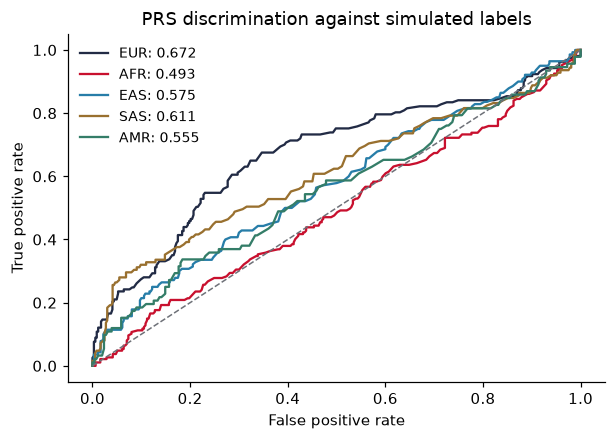

In [7]:
y = meta['phenotype'].to_numpy()
def auc_ci(y_true, values, repetitions=1000, seed=6900):
    # Resample cases and controls separately; descriptive, unadjusted for kinship.
    r=np.random.default_rng(seed)
    pos,neg=np.flatnonzero(y_true==1),np.flatnonzero(y_true==0)
    if min(len(pos),len(neg)) == 0: return np.nan,np.nan
    stats=[]
    for _ in range(repetitions):
        idx=np.r_[r.choice(pos,len(pos),replace=True),r.choice(neg,len(neg),replace=True)]
        stats.append(roc_auc_score(y_true[idx],values[idx]))
    return tuple(np.quantile(stats,[0.025,0.975]))

auc_rows=[]
for k,pop in enumerate(['Overall']+list(POP_COLORS)):
    m=np.ones(len(meta),dtype=bool) if pop=='Overall' else (meta.ancestry==pop).to_numpy()
    a=roc_auc_score(y[m],prs_z[m]);low,high=auc_ci(y[m],prs_z[m],seed=6900+k)
    auc_rows.append({'group':pop,'n':int(m.sum()),'cases':int(y[m].sum()),
                     'auc':a,'ci_lower':low,'ci_upper':high})
auc_table=pd.DataFrame(auc_rows).set_index('group')
display(auc_table.round(4));auc_table.to_csv('results/auc_by_ancestry.csv')
fig,ax=plt.subplots(figsize=(5.7,4.1))
for pop,c in POP_COLORS.items():
    m=(meta.ancestry==pop).to_numpy();fpr,tpr,_=roc_curve(y[m],prs_z[m])
    ax.plot(fpr,tpr,color=c,label=f"{pop}: {auc_table.loc[pop,'auc']:.3f}")
ax.plot([0,1],[0,1],ls='--',color=NU_GREY,lw=1)
ax.set(xlabel='False positive rate',ylabel='True positive rate',title='PRS discrimination against simulated labels')
ax.legend(frameon=False,fontsize=9);fig.tight_layout();save_figure(fig,'02_roc_by_ancestry');plt.show()


### My interpretation of discrimination

The PRS AUC is **0.599 overall**, **0.672 EUR**, **0.493 AFR**, **0.575 EAS**, **0.611 SAS**, and **0.555 AMR**. AUC measures ranking: an AUC of 0.672 means a randomly selected simulated case has a higher score than a randomly selected simulated control about 67% of the time, counting ties as half. It does not mean 67% diagnostic accuracy or a 67% disease probability.

EUR has the highest point estimate and AFR is near chance (aligns with random perturbation for AFR samples in the data). AFR's descriptive bootstrap interval includes 0.5, as does AMR's; I would not interpret 0.493 as evidence of a useful reversed score. The intervals come from 1,000 stratified case/control resamples, do not account for possible relatedness, and do not constitute formal pairwise ancestry comparisons. The overall AUC combines within-group ranking and between-group differences, so it cannot establish that the score works for every group.


## 3.5 Calibration by ancestry  

Fit the risk model **in EUR only**, apply it to everyone, and draw one calibration curve per ancestry. A model honest in EUR is often not honest elsewhere. The helper is provided.

In [8]:
def calibration_points(y, p, bins=5):
    edges = np.quantile(p, np.linspace(0,1,bins+1)); edges[-1]+=1e-9
    idx = np.clip(np.digitize(p, edges)-1, 0, bins-1)
    xs, ys = [], []
    for b in range(bins):
        m = idx==b
        if m.sum() > 5: xs.append(p[m].mean()); ys.append(y[m].mean())
    return np.array(xs), np.array(ys)

EUR-only model: intercept=-0.865538, coefficient=0.677213


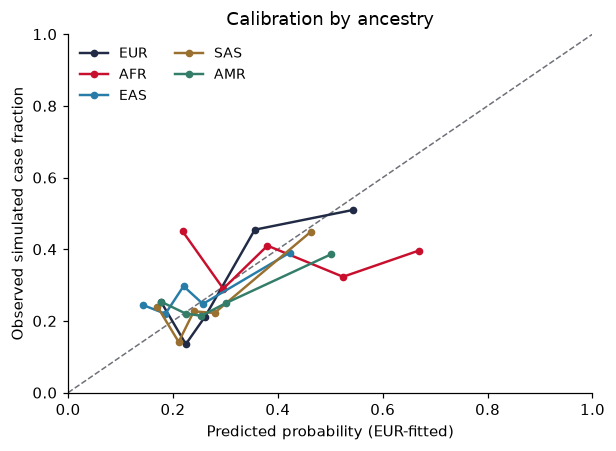

,n,mean_predicted,observed_simulated,predicted_minus_observed,brier_score
ancestry,,,,,
EUR,500,0.3140,0.3140,0.0000,0.1951
AFR,500,0.4177,0.3740,0.0437,0.2661
EAS,500,0.2458,0.2800,-0.0342,0.1991
SAS,489,0.2730,0.2556,0.0174,0.1789
AMR,347,0.2930,0.2651,0.0279,0.1969


EUR points reuse the fitting sample: apparent calibration, not independent validation.


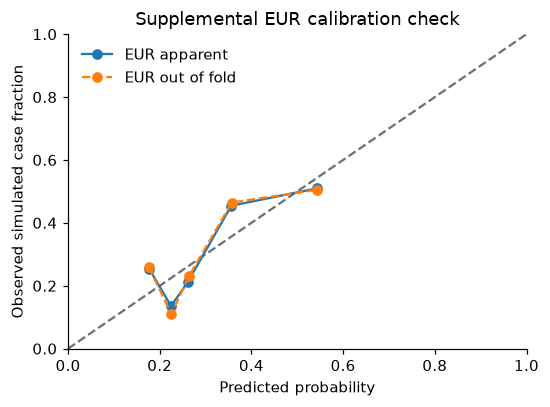

EUR out-of-fold Brier score: 0.1961


In [9]:
prs_z=meta['prs'].to_numpy();y=meta['phenotype'].to_numpy()
eur=(meta.ancestry=='EUR').to_numpy()
model=LogisticRegression(max_iter=2000,random_state=6900)
model.fit(prs_z[eur].reshape(-1,1),y[eur])
p_hat=model.predict_proba(prs_z.reshape(-1,1))[:,1]
meta['eur_fitted_probability']=p_hat
print(f'EUR-only model: intercept={model.intercept_[0]:.6f}, coefficient={model.coef_[0,0]:.6f}')
cal_rows=[]
fig,ax=plt.subplots(figsize=(5.7,4.2))
ax.plot([0,1],[0,1],ls='--',color=NU_GREY,lw=1)
for pop,c in POP_COLORS.items():
    m=(meta.ancestry==pop).to_numpy()
    xs,ys=calibration_points(y[m],p_hat[m])
    ax.plot(xs,ys,marker='o',ms=4,color=c,lw=1.6,label=pop)
    cal_rows.append({'ancestry':pop,'n':int(m.sum()),'mean_predicted':p_hat[m].mean(),
        'observed_simulated':y[m].mean(),'predicted_minus_observed':p_hat[m].mean()-y[m].mean(),
        'brier_score':brier_score_loss(y[m],p_hat[m])})
ax.set(xlabel='Predicted probability (EUR-fitted)',ylabel='Observed simulated case fraction',
       title='Calibration by ancestry',xlim=(0,1),ylim=(0,1))
ax.legend(frameon=False,ncol=2,fontsize=9)
fig.tight_layout();save_figure(fig,'03_calibration_by_ancestry');plt.show()
calibration_table=pd.DataFrame(cal_rows).set_index('ancestry')
display(calibration_table.round(4));calibration_table.to_csv('results/calibration_summary.csv')
print('EUR points reuse the fitting sample: apparent calibration, not independent validation.')
# Supplemental EUR out-of-fold calibration uses training-fold scaling and no non-EUR outcomes.
eur_cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=6900)
eur_oof=cross_val_predict(make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000)),
    prs[eur].reshape(-1,1),y[eur],cv=eur_cv,method='predict_proba')[:,1]
fig,ax=plt.subplots(figsize=(5.1,3.8));ax.plot([0,1],[0,1],'--',color=NU_GREY)
for label,pp,style in [('EUR apparent',p_hat[eur],'-'),('EUR out of fold',eur_oof,'--')]:
    xs,ys=calibration_points(y[eur],pp);ax.plot(xs,ys,style,marker='o',label=label)
ax.set(xlabel='Predicted probability',ylabel='Observed simulated case fraction',
       title='Supplemental EUR calibration check',xlim=(0,1),ylim=(0,1))
ax.legend(frameon=False);fig.tight_layout();save_figure(fig,'04_eur_oof_calibration');plt.show()
print(f'EUR out-of-fold Brier score: {brier_score_loss(y[eur],eur_oof):.4f}')


### My interpretation of calibration

I fitted a logistic model in EUR only and applied that unchanged model to every group. A point above the diagonal means underprediction; below it means overprediction. Mean predicted versus observed **simulated** case fractions are EUR **31.4% vs 31.4%** (I would generally not use same samples set for fitting and evaluation as it introduces bias in the model and model can cheat by memorizing), AFR **41.8% vs 37.4%**, EAS **24.6% vs 28.0%**, SAS **27.3% vs 25.6%**, and AMR **29.3% vs 26.5%**.

EUR is calibrated in the large almost exactly because the model was fitted and evaluated on those same EUR outcomes. Its individual calibration bins do **not** all lie on the diagonal. The supplemental EUR out-of-fold curve avoids this same-person fitting/evaluation; its Brier score is **0.1961**, versus **0.1951** apparent. Neither is external clinical validation. Brier score mixes calibration and predictive resolution and also depends on outcome prevalence, so I do not use its cross-group ranking as a pure calibration comparison.

The distinction is clearest in SAS: its AUC of **0.611** shows some ranking ability, but the EUR model overpredicts the average simulated case fraction by **1.7 percentage points**. EAS has modest ranking while its average probability is too low by **3.4 points**. AFR has poor ranking and a flattened, non-monotonic calibration curve; high predicted probabilities are not matched by high observed fractions. A model can rank people reasonably and still give the wrong probabilities. Matching the group average also cannot guarantee calibration within risk bins.


## 3.6 Does the PRS add to age alone?  

In [10]:
# Identical five stratified folds for a paired comparison; no shuffle, matching cv=5.
# Scale raw age and raw PRS INSIDE each training fold to avoid preprocessing leakage.
cv=StratifiedKFold(n_splits=5,shuffle=False)
splits=list(cv.split(meta,y))
estimator=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,random_state=6900))
X_age=meta[['age']].to_numpy()
X_age_prs=meta[['age','prs_raw']].to_numpy()
age_scores=cross_val_score(estimator,X_age,y,cv=splits,scoring='roc_auc')
combined_scores=cross_val_score(estimator,X_age_prs,y,cv=splits,scoring='roc_auc')
auc_age,auc_age_prs=age_scores.mean(),combined_scores.mean()
cv_table=pd.DataFrame({'fold':np.arange(1,6),'auc_age':age_scores,
                       'auc_age_prs':combined_scores,'difference':combined_scores-age_scores})
display(cv_table.round(4));cv_table.to_csv('results/cross_validation_folds.csv',index=False)
print(f'AUC age only:  {auc_age:.3f} (fold SD {age_scores.std(ddof=1):.3f})')
print(f'AUC age + PRS: {auc_age_prs:.3f} (fold SD {combined_scores.std(ddof=1):.3f})')
print(f'Incremental AUC: {auc_age_prs-auc_age:.3f}')
# Within-group CV checks whether a pooled gain hides unequal subgroup gains.
group_cv=[]
for pop in POP_COLORS:
    m=(meta.ancestry==pop).to_numpy();yp=y[m]
    folds=list(StratifiedKFold(n_splits=5,shuffle=True,random_state=6900).split(X_age[m],yp))
    a=cross_val_score(estimator,X_age[m],yp,cv=folds,scoring='roc_auc').mean()
    b=cross_val_score(estimator,X_age_prs[m],yp,cv=folds,scoring='roc_auc').mean()
    group_cv.append({'ancestry':pop,'auc_age':a,'auc_age_prs':b,'difference':b-a})
group_cv=pd.DataFrame(group_cv).set_index('ancestry')
display(group_cv.round(4));group_cv.to_csv('results/supplemental_within_group_cv.csv')
meta.to_csv('results/scored_cohort.csv',index=False)
summary={'n':len(meta),'cutoff':float(cutoff),'selected':int(meta.above_pooled_cutoff.sum()),
    'ties_at_cutoff':int((meta['prs']==cutoff).sum()),
    'raw_prs_mean':float(prs.mean()),'raw_prs_sd':float(prs.std()),'harmonization':harm,
    'auc_age':float(auc_age),'auc_age_prs':float(auc_age_prs),
    'delta_auc':float(auc_age_prs-auc_age),'eur_intercept':float(model.intercept_[0]),
    'eur_coefficient':float(model.coef_[0,0]),'eur_oof_brier':float(brier_score_loss(y[eur],eur_oof))}
Path('results/summary.json').write_text(json.dumps(summary,indent=2))
versions={'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
          'scipy':scipy.__version__,'scikit_learn':sklearn.__version__}
Path('results/environment.json').write_text(json.dumps(versions,indent=2))
print('Analysis tables, fingerprints, figures and software versions saved.')


,fold,auc_age,auc_age_prs,difference
0,1,0.5595,0.5193,-0.0402
1,2,0.5744,0.6669,0.0925
2,3,0.5863,0.5971,0.0108
3,4,0.5675,0.6830,0.1156
4,5,0.5230,0.6235,0.1005


AUC age only:  0.562 (fold SD 0.024)
AUC age + PRS: 0.618 (fold SD 0.065)
Incremental AUC: 0.056


,auc_age,auc_age_prs,difference
ancestry,,,
EUR,0.5635,0.6803,0.1167
AFR,0.5645,0.5560,-0.0085
EAS,0.5760,0.6091,0.0330
SAS,0.5279,0.6171,0.0892
AMR,0.5734,0.5743,0.0009


Analysis tables, fingerprints, figures and software versions saved.


### My interpretation of incremental value

Using the same five stratified folds, mean AUC increases from **0.562** for age alone to **0.618** for age plus PRS: **ΔAUC = 0.056**. Scaling is fitted only on each training fold, and published PRS weights are fixed. I used unshuffled folds to match the starter's `cv=5` convention. Because the input is ordered by ancestry, these folds can have different ancestry mixtures; this is a class-stratified classroom comparison, not ancestry-balanced or external validation.

The improvement is not uniform: fold 1 decreases by **0.040**, and the five differences range from **−0.040 to +0.116**. Supplemental models fitted separately within each ancestry give ΔAUC **+0.117 EUR**, **−0.009 AFR**, **+0.033 EAS**, **+0.089 SAS**, and **+0.001 AMR**. These are separate within-group experiments, not evaluations of a single EUR-trained model, and are descriptive rather than formal significance tests. The pooled improvement does not establish useful incremental prediction for AFR or AMR.

Since both age and disease labels were simulated, this evaluates recovery of the supplied simulation signal. AUC gain alone does not show better health outcomes, net clinical benefit or treatment usefulness.


## 3.7 Final interpretation

### 1. Why portability changes

The calculation is the same in every group, but the relationship between a measured tag variant and a disease-relevant variant can differ. **Linkage disequilibrium (LD)** is correlation between alleles at different loci. A tag that tracks a causal allele well in EUR can track it less well elsewhere. Allele frequencies also change the score distribution, the variance contributed by a variant and how precisely its effect was estimated. A European-derived score can therefore lose predictive accuracy without implying that disease biology is absent in another group. Unequal representation in score development is a scientific and equity concern [1,3].

In this assignment, the README says hidden causal variants were selected for EUR LD r² > 0.6; mean tag–causal r² was 0.82 in EUR and 0.44 in AFR. These figures are supplied design information, not results I could recompute from the 22-tag panel. The README also states that noise was tuned to yield EUR AUC near 0.67, so recovering this pattern is a teaching demonstration rather than independent evidence of clinical validity. The phenotype uses common causal-effect rules and a pooled liability threshold, making LD and frequency differences central to the intended portability demonstration.

### 2. One threshold and fairness

The single cutoff selects 27.8% of AFR but 7.8% of EUR and 2.2% of EAS. Applying it unchanged could create very different referral burdens, anxiety, costs and missed opportunities for assessment. The near-chance AFR AUC means a high selection rate cannot be defended as accurate identification of cases here. I would not call an equal numerical rule clinically equitable without examining subgroup calibration, errors, benefits, harms and access. Ancestry-specific percentiles alone are not a solution unless the underlying reference data/sequencing is not addressed.

### 3. Discrimination and calibration

AUC asks whether cases rank above controls; calibration asks whether a predicted probability agrees with observed frequency. SAS has AUC 0.611 yet average overprediction; EAS has AUC 0.575 yet average underprediction. EUR's mean calibration looks good partly because its outcomes trained the model, while its bins still fluctuate. Therefore I need both measures and an independent validation design (using different data for model fitting, model hyperparameter selection and evaluation), not one summary number.

Validation must cover relevant ancestries, admixed individuals, sex and age groups, with appropriate LD/ancestry information and adequate cases.

### 4. APOE artifact versus biology

The README reports that the hidden proxy assigned to rs429358 has r² about 0.01 with that tag in AFR. Simulated liability depends on the hidden proxy, so the observed APOE tag is poorly informative in this design. That does **not** show that APOE ε4 is unimportant in African-ancestry people. Research in African American cohorts supports ε4-associated risk and shows that local ancestry can modify its magnitude [4]. The provided score is an additive SNP score, not a phased APOE haplotype model.

### Sources

[1] PGS Catalog. PGS000334, GRSfull_22, 22 variants, GRCh37. https://www.pgscatalog.org/score/PGS000334/ (checked 29 October 2026). Catalog records predominantly European discovery ancestry and European evaluation; I use “European-derived” as shorthand, not a claim that every discovery participant was European.

[2] Zhang Q et al. Risk prediction of late-onset Alzheimer’s disease implies an oligogenic architecture. Nature Communications 11, 4799 (2020). https://doi.org/10.1038/s41467-020-18534-1

[3] Martin AR et al. Clinical use of current polygenic risk scores may exacerbate health disparities. Nature Genetics 51, 584–591 (2019). https://doi.org/10.1038/s41588-019-0379-x

[4] Rajabli F et al. Ancestral origin of ApoE ε4 Alzheimer disease risk in Puerto Rican and African American populations. PLOS Genetics 14, e1007791 (2018). https://doi.org/10.1371/journal.pgen.1007791

The supplied course README documents the 1000 Genomes Phase 3 GRCh37 extraction, cohort selection and simulation design; it is preserved at `data/README.md`. The calculations in this notebook are newly executed on the supplied CSV files.
